# 02 · DeepONet：输入函数与查询坐标分开编码（中级）

**前置：** 01；矩阵乘法。**目标：** 理解 branch/trunk 两个网络，并在未参与训练的输出坐标上预测新函数。

PDE 与上一章相同。DeepONet 写成 $v_\theta(f,x)=4x(1-x)\sum_{j=1}^p b_j(f)t_j(x)$。branch 读取固定传感器上的 forcing；trunk 读取查询坐标。两个网络共同学习系数和基函数。这里的边界因子是教学扩展。

参考：[DeepONet 原始论文](https://arxiv.org/abs/1910.03193)。

## 原理详解 A：从基函数展开到 DeepONet

### A.1 系数依赖输入函数，基函数依赖查询坐标

普通基展开写成 $u(x)=\sum_jc_j\phi_j(x)$。对一族 PDE，系数会随着 forcing 改变，因此可以写成
$$
u(f,x)\approx\sum_{j=1}^pb_j(f)t_j(x).
$$
DeepONet 用 branch 学 $b_j$，用 trunk 学 $t_j$。branch 接收 forcing 的采样值，而不是数学意义上的整个无限维函数；trunk 接收坐标，得到连续可查询的输出。

本章预测 $v=\pi^2u$，再使用硬边界因子：
$$
v_\theta(f,x)=4x(1-x)\sum_{j=1}^pb_{\theta,j}(P_sf)t_{\theta,j}(x).
$$
这个边界因子属于本教程的结构选择，并非所有 DeepONet 的必需部分。原始架构也常加入输出偏置；本章实现没有独立输出偏置。

### A.2 与 Poisson 的精确展开对应

解析解是
$$
v(f,x)=\sum_{k=1}^K\frac{a_k(f)}{k^2}\sin(k\pi x).
$$
可以把 $a_k(f)/k^2$ 看成 branch 需要推断的系数，把正弦函数看成理想 trunk 基。实际网络同时学习两者，并不把这些系数或解析基直接作为网络输入。

有限 latent 维度 $p$ 限制了输出函数的展开容量，但不是“只能处理 p 个训练样本”。对于当前结构，所有预测函数属于至多 p 个有效输出基的张成空间；复杂函数族可能需要更大的 p。

来源：[DeepONet 原论文](https://arxiv.org/abs/1910.03193)。

## 原理详解 B：矩阵乘法、共享查询与计算复用

设函数批次大小为 $B$、传感器数为 $S$、查询点数为 $Q$、latent 维度为 $p$。

| 步骤 | 数学对象 | 张量形状 |
|---|---|---|
| forcing 采样 | $P_sf$ | $B\times S$ |
| branch 编码 | $b(f)$ | $B\times p$ |
| 查询坐标 | $x_q$ | $Q\times1$ |
| trunk 编码 | $t(x_q)$ | $Q\times p$ |
| 特征内积 | $b(f)t(x_q)^T$ | $B\times Q$ |
| 边界因子 | $4x_q(1-x_q)$ | $1\times Q$ |

乘法中的转置很重要：$[B,p]@[p,Q]$ 才得到所有函数和所有查询点的笛卡尔积。若只需要逐样本配对查询，可以计算逐行内积，但这与当前完整输出网格的接口不同。

同一 forcing 在 33 点、129 点或随机点查询时，branch 输入与权重不变。理论上可缓存 branch 编码，再计算新 trunk；本章为了接口简单，调用时会重新计算 branch。模型能接收不同 Q，不代表计算成本不随 Q 增长：特征内积约需要 $O(BQp)$ 运算。

输出坐标可变，是模型定义层面的灵活性；这些新坐标上的准确性仍要靠解析参考解评估。

## 原理详解 C：传感器信息、插值与函数泛化

若 $f_1(s_i)=f_2(s_i)$ 对所有传感器都成立，branch 得到完全相同输入，故对任何查询点都输出同一个预测。模型无法恢复传感器没有观测到的信息。增加 trunk 深度或查询密度不能消除这个瓶颈。

应分开理解三类实验：

1. **新函数测试：** 更换系数，但输入传感器和输出坐标布局保持不变。
2. **新坐标测试：** 保持同一输入函数，改变输出查询坐标。
3. **新传感器测试：** 改变输入观测数量或布局，这通常要求新的 branch 接口或显式传感器编码。

本章密网格实验同时使用未见过的测试函数与新输出坐标，但输入仍是原 33 个传感器。因此它证明的是当前函数分布上的函数与查询泛化，不是任意输入网格的兼容性。

均匀随机查询的经验误差可以近似域内平均误差；若人为在局部放更多查询点，损失就会更重视该区域。想保持统一的积分意义，需要定义查询分布或求积权重。

**推导自检：** 给定 branch 输出 $[8,32]$、trunk 输出 $[129,32]$，最终应为 $[8,129]$。若希望输出两个物理场，需明确是两个独立内积、额外输出通道，还是共享 latent 后的多头投影。

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / "tutorial_utils.py").exists():
    ROOT = ROOT / "neural_operator_tutorials"
if not (ROOT / "tutorial_utils.py").exists():
    raise FileNotFoundError("Please start Jupyter in PINO or neural_operator_tutorials")
sys.path.insert(0, str(ROOT))
import torch
get_ipython().run_line_magic('matplotlib', 'inline')
from tutorial_utils import *
seed_all()
print("device:", DEVICE, "| smoke:", SMOKE)


device: cpu | smoke: False


In [2]:
ntrain,ntest = counts()
sensors = torch.linspace(0,1,33)
query = torch.linspace(0,1,33)
atrain,aval,atest = torch.randn(ntrain,5),torch.randn(ntest,5),torch.randn(ntest,5)
ftrain,_ = poisson_data(atrain,sensors)
fval,_ = poisson_data(aval,sensors)
ftest,_ = poisson_data(atest,sensors)
_,vtrain = poisson_data(atrain,query)
_,vval = poisson_data(aval,query)
_,vtest = poisson_data(atest,query)

## 1. 分支特征与主干特征做内积

branch 的输出是 $[B,p]$，trunk 是 $[Q,p]$，乘法后得到 $[B,Q]$。同一个 branch 编码可在很多输出点复用。不要把函数与坐标拼成一个没有解释的巨大向量。

epoch    1 | train MSE 1.754e-01 | val relative L2 0.544


epoch   50 | train MSE 3.896e-03 | val relative L2 0.137


epoch  100 | train MSE 2.787e-03 | val relative L2 0.122


epoch  150 | train MSE 1.446e-03 | val relative L2 0.095


epoch  200 | train MSE 1.204e-03 | val relative L2 0.055


epoch  250 | train MSE 8.652e-04 | val relative L2 0.062


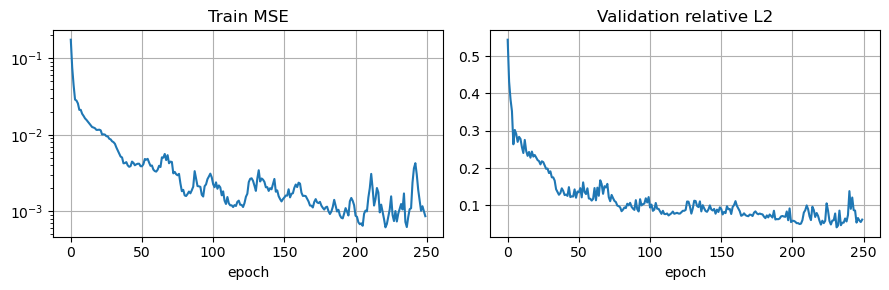

In [3]:
class DeepONet(nn.Module):
    def __init__(self,nsensors,latent=32):
        super().__init__()
        self.branch = nn.Sequential(nn.Linear(nsensors,64),nn.Tanh(),nn.Linear(64,latent))
        self.trunk = nn.Sequential(nn.Linear(1,64),nn.Tanh(),
                                   nn.Linear(64,64),nn.Tanh(),nn.Linear(64,latent))
    def forward(self,f,x):
        b = self.branch(f)
        t = self.trunk(x[:,None])
        return (b@t.T)*(4*x*(1-x))[None,:]

model = DeepONet(len(sensors))
predict = lambda m,f: m(f,query.to(f.device))
history = fit(model,ftrain,vtrain,fval,vval,steps=epochs(250),predict=predict)
plot_history(history)

## 2. 新函数 + 更密的查询坐标

输入仍然是原来的 33 个传感器，输出可以是 129 个点。参考解必须用**同一组测试系数**重新在新网格上采样，而不能另外随机生成。此实验检查输出坐标泛化，不检查输入传感器数量变化。

Test relative L2: mean=0.0691, median=0.0594, max=0.3791


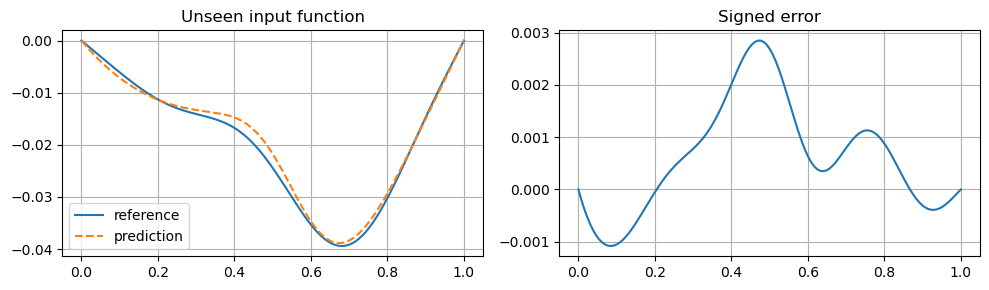

33 sensors -> 129 query points


In [4]:
dense = torch.linspace(0,1,129)
_,truth = poisson_data(atest,dense)
dense_predict = lambda m,f: m(f,dense.to(f.device))
pred,error = report(model,ftest,truth,predict=dense_predict)
plot_1d(dense,truth/torch.pi**2,pred/torch.pi**2)
assert pred[:,[0,-1]].abs().max()<1e-7
print("33 sensors ->",pred.shape[-1],"query points")

## 3. 查询任意位置而非必须均匀网格

下面使用随机、已排序的坐标，仍然用解析解计算参考值。branch 感知函数的能力受传感器数量限制；trunk 的连续输入形式不会恢复已经被传感器漏掉的高频信息。

Test relative L2: mean=0.0688, median=0.0594, max=0.3409


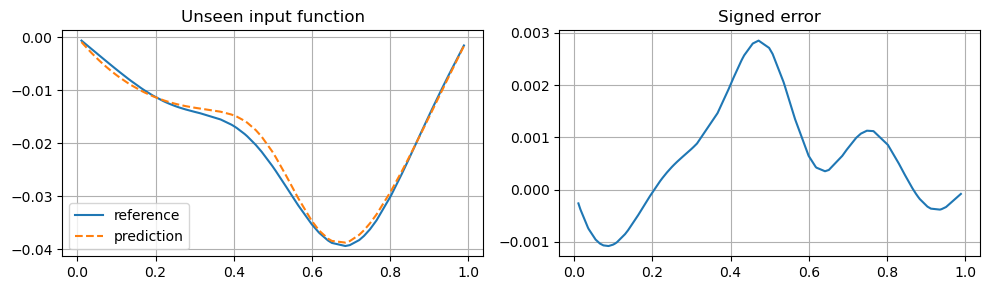

In [5]:
random_query = torch.rand(75).sort().values
_,random_truth = poisson_data(atest,random_query)
random_pred,_ = report(model,ftest,random_truth,
    predict=lambda m,f: m(f,random_query.to(f.device)))
plot_1d(random_query,random_truth/torch.pi**2,random_pred/torch.pi**2)

**练习：** ① 修改 latent 维度，看秩限制如何影响误差；② 给传感器值加噪声；③ 减少传感器到 9 个并加入高频 forcing。**自检：** 能更换输出查询点，是否意味着也能直接更换 branch 的输入维数？答案是否定的。

下一章采用 Fourier 层，让同一套参数作用于不同长度的规则输入网格。